In [7]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import os
from ne_aligned_utils.plot import plot_aligned_embedding

env: CUDA_VISIBLE_DEVICES=1
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:

seeds = [0, 1, 2, 3, 4]
dataset = "fig1"

tol = 1e-12
maxIter = int(1e4)

eps_times = 1

embd_dim = 2
init_str = "random"  # "pca" or "random"
init_scale = 1

batch_size = 2**14
negative_samples = 5
n_epochs = 200
loss_mode = "infonce"
alignment = True
sample_pos = "per_point"
sparsify = None

res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)


n0 = 1000
n1 = 5000
colors =  ["r"]*n0 + ["b"]*n1


In [39]:
embds = []

for seed in seeds:
    filename = os.path.join(res_path,
                        f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                        f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                        f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
    a = np.load(os.path.join(res_path, filename))
    embds.append(a["embd"])

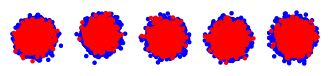

In [40]:
fig, ax = plt.subplots(1, len(seeds), figsize=(4, 4))

for seed in seeds:
    plot_aligned_embedding(embds[seed][::-1],
                           n0,
                           color =colors[::-1],
                           fig_name=None,
                           shuffle=True,
                           ax=ax[seed],
                           )

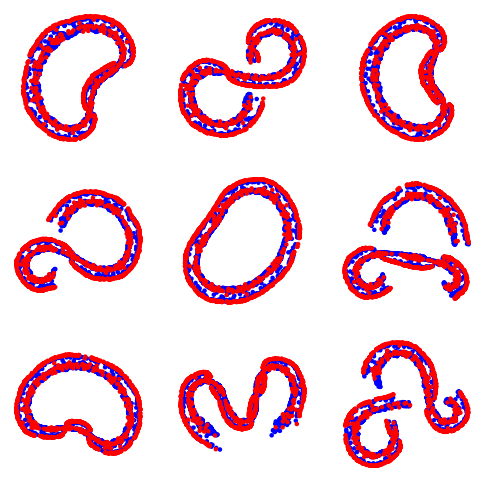

In [31]:
eps_times_list = [1, 10, 100]

fig, ax = plt.subplots(len(seeds), len(eps_times_list), figsize=(6, 6))

for i, seed in enumerate(seeds):
    for j, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                            f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                            f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               fig_name=None,
                               shuffle=False,
                               ax=ax[i, j],
                               )